1. Definición del problema CREDIT_LIMIT

In [91]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

In [92]:
from sklearn import set_config
set_config (transform_output="pandas")
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, KFold, train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler,StandardScaler,RobustScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import KNNImputer
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score, root_mean_squared_error,mean_absolute_error
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

2. Recolección de datos

In [93]:
path = r"C:\Users\kevin\Downloads\CC GENERAL.csv"
data = pd.read_csv(path, sep=",",header=0,index_col='CUST_ID')
data.head()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
CUST_ID,,,,,,,,,,,,,,,,,
C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


3. Comprensión de los datos (EDA)

In [94]:
data.info()
data.shape

<class 'pandas.DataFrame'>
Index: 8950 entries, C10001 to C19190
Data columns (total 17 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   BALANCE                           8950 non-null   float64
 1   BALANCE_FREQUENCY                 8950 non-null   float64
 2   PURCHASES                         8950 non-null   float64
 3   ONEOFF_PURCHASES                  8950 non-null   float64
 4   INSTALLMENTS_PURCHASES            8950 non-null   float64
 5   CASH_ADVANCE                      8950 non-null   float64
 6   PURCHASES_FREQUENCY               8950 non-null   float64
 7   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 8   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 9   CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 10  CASH_ADVANCE_TRX                  8950 non-null   int64  
 11  PURCHASES_TRX                     8950 non-null   int64  
 12  CREDIT_LIMIT   

(8950, 17)

In [95]:
data.corr(numeric_only=True)["CREDIT_LIMIT"].sort_values(ascending=False).drop("CREDIT_LIMIT")

BALANCE                             0.531283
PAYMENTS                            0.421861
PURCHASES                           0.356963
ONEOFF_PURCHASES                    0.319724
CASH_ADVANCE                        0.303985
ONEOFF_PURCHASES_FREQUENCY          0.295038
PURCHASES_TRX                       0.272882
INSTALLMENTS_PURCHASES              0.256499
CASH_ADVANCE_TRX                    0.149700
TENURE                              0.139167
CASH_ADVANCE_FREQUENCY              0.132616
MINIMUM_PAYMENTS                    0.126671
PURCHASES_FREQUENCY                 0.119788
BALANCE_FREQUENCY                   0.095843
PURCHASES_INSTALLMENTS_FREQUENCY    0.060755
PRC_FULL_PAYMENT                    0.055672
Name: CREDIT_LIMIT, dtype: float64

Text(0.5, 1.0, 'Heatmap Credit Card Dataset for Clustering')

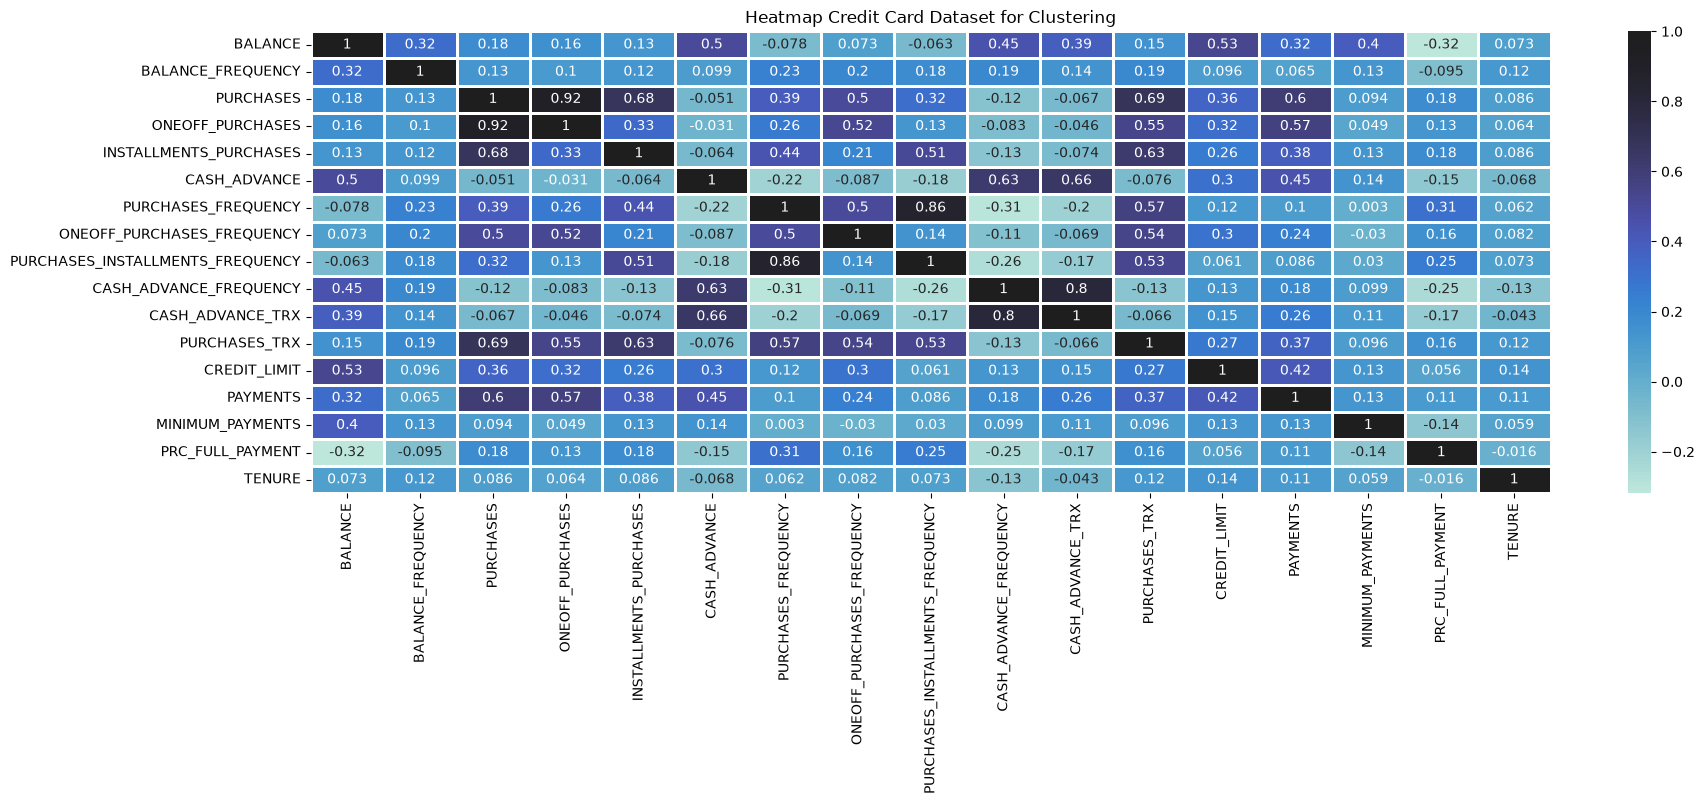

In [96]:
#Se grafica de acuerdo a la correlacion con Y sin consioderar srt's
plt.figure(figsize=(20,6))
ax=sns.heatmap(data=(data.corr()),
               center= True,
               annot=True,
               linewidths=1,
               cmap= "icefire",
               fmt= ".2g"                          
)
ax.set_title("Heatmap Credit Card Dataset for Clustering")

4. Preparación de datos

In [97]:
data.columns

Index(['BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES',
       'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY',
       'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY',
       'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX',
       'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT',
       'TENURE'],
      dtype='str')

In [98]:
# identificando nan
data_nan = data.isna().sum().sort_values(ascending=False).to_frame(name="Nan_values")
data_nan["Zeros_values"] = (data==0).sum()
data_nan

,Nan_values,Zeros_values
MINIMUM_PAYMENTS,313,0
CREDIT_LIMIT,1,0
BALANCE,0,80
BALANCE_FREQUENCY,0,80
PURCHASES,0,2044
CASH_ADVANCE,0,4628
PURCHASES_FREQUENCY,0,2043
ONEOFF_PURCHASES,0,4302
INSTALLMENTS_PURCHASES,0,3916
PURCHASES_INSTALLMENTS_FREQUENCY,0,3915


In [99]:
print(f"De acuerdo con lo validado, la columna de Zeros_values corresponde a ceros reales de acuerdo al contexto del dataset,",
      f"\npero considerando la columna de Nan_values {data_nan["Nan_values"].idxmax()} con {max(data_nan["Nan_values"])} es candidato a imputación con la KNNImputer,",
      f"\nconsiderando que el segundo elemento es {data_nan["Nan_values"].sort_values(ascending=False).index[1]} el target y solo contiene {data_nan.loc["CREDIT_LIMIT", "Nan_values"]} elemento, se optara por la eliminacion de la fila")

De acuerdo con lo validado, la columna de Zeros_values corresponde a ceros reales de acuerdo al contexto del dataset, 
pero considerando la columna de Nan_values MINIMUM_PAYMENTS con 313 es candidato a imputación con la KNNImputer, 
considerando que el segundo elemento es CREDIT_LIMIT el target y solo contiene 1 elemento, se optara por la eliminacion de la fila


In [100]:
#Elimninacion de nan si es igual o menor que 1
cols_1nan = data_nan.index[data_nan["Nan_values"]<=1].tolist()
data = data.dropna(subset=cols_1nan)

In [101]:
#segmentacion de datos
target = "CREDIT_LIMIT"
y=data[target]
X= data.drop(columns=target)
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state= 42,train_size=.8)

In [102]:
#Escalar para imputar
inv_scaler = StandardScaler()
X_train_inv = inv_scaler.fit_transform(X_train)
X_test_inv = inv_scaler.transform(X_test)

In [103]:
#Identificar Nan en X
X_nan = X.isna().sum().sort_values(ascending=False).to_frame(name="Nan_values_x")
cols_nan_X = X_nan[X_nan["Nan_values_x"] > 0].index.tolist()
print(f"Columnas a imputar {cols_nan_X}")

Columnas a imputar ['MINIMUM_PAYMENTS']


In [104]:
#Definiendo instancia del imputer
imputer = KNNImputer(n_neighbors=5)

#Reemplazar Nan en X
X_train_inv = imputer.fit_transform(X_train_inv)
X_test_inv = imputer.transform(X_test_inv)
imp_cols = X_test_inv.columns.to_list()
print(f"Columnas imputadas {imp_cols}")

Columnas imputadas ['BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']


In [105]:
#Revertir escalado
X_train = pd.DataFrame(inv_scaler.inverse_transform(X_train_inv),
                       columns=X_train_inv.columns, 
                       index=X_train_inv.index)
X_test = pd.DataFrame(inv_scaler.inverse_transform(X_test_inv),
                      columns=X_test_inv.columns, 
                      index= X_test_inv.index)

Considerar que este escalado se realizo unicamente para evitar la fuga de datos al momento de realizar la imputación

5. Selección de features

In [106]:
corr_imp = X_train.join(y_train).corr()[target].drop(target).sort_values(ascending = False)
corr_imp

BALANCE                             0.537292
PAYMENTS                            0.418545
PURCHASES                           0.346964
ONEOFF_PURCHASES                    0.316800
CASH_ADVANCE                        0.300366
ONEOFF_PURCHASES_FREQUENCY          0.290229
PURCHASES_TRX                       0.272424
INSTALLMENTS_PURCHASES              0.243295
CASH_ADVANCE_TRX                    0.151219
TENURE                              0.144970
MINIMUM_PAYMENTS                    0.134923
CASH_ADVANCE_FREQUENCY              0.129497
PURCHASES_FREQUENCY                 0.118712
BALANCE_FREQUENCY                   0.093449
PURCHASES_INSTALLMENTS_FREQUENCY    0.060298
PRC_FULL_PAYMENT                    0.054210
Name: CREDIT_LIMIT, dtype: float64

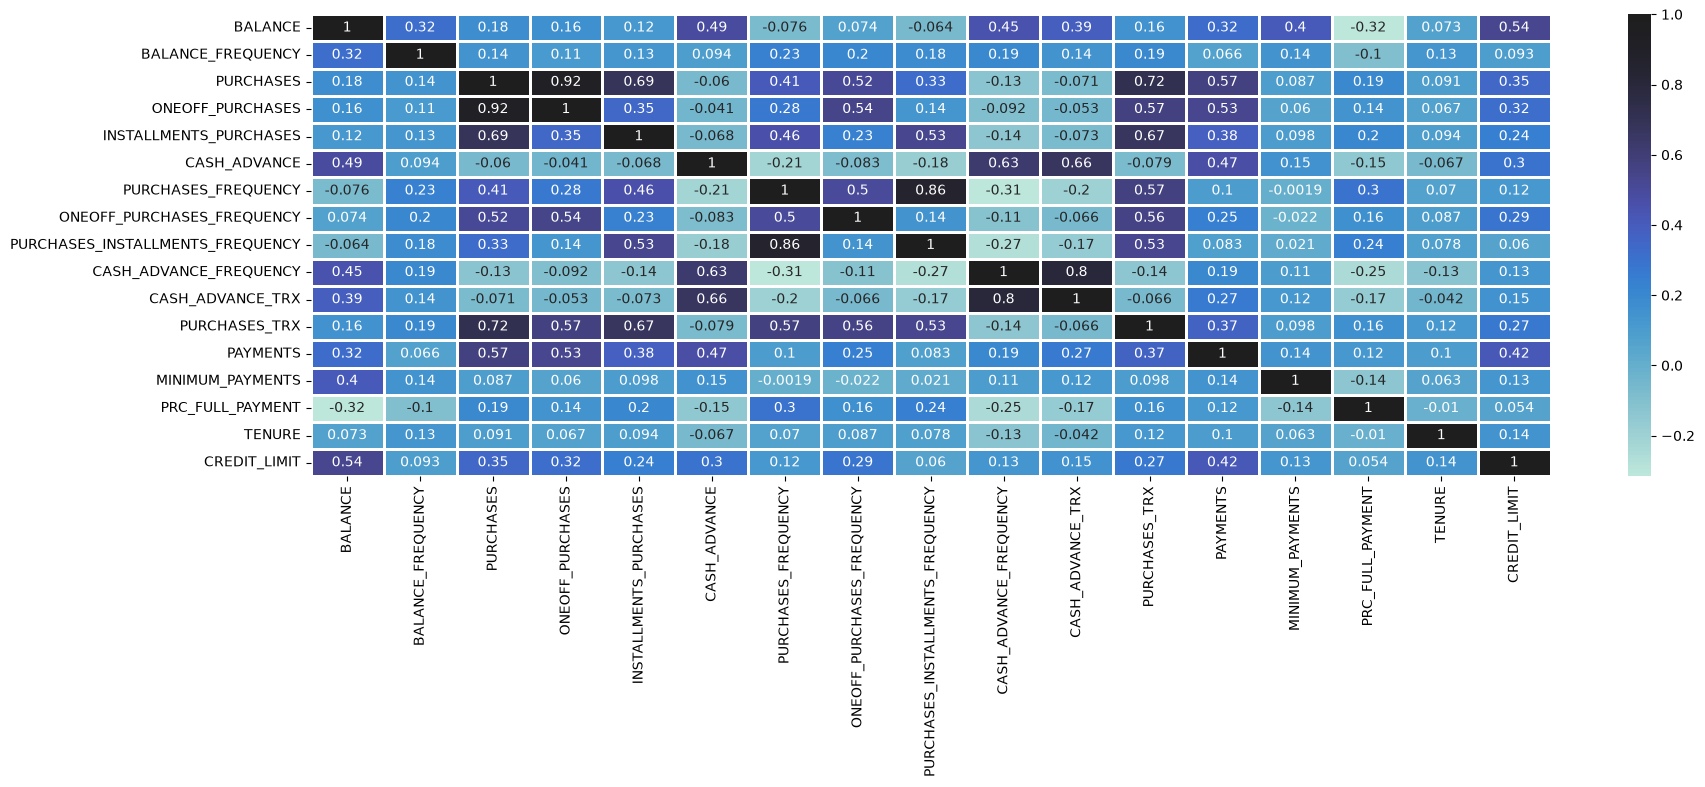

In [107]:
plt.figure(figsize=(20,6))
ax2 = sns.heatmap(data= X_train.join(y_train).corr(),
                  center= True,
                  annot=True,
                  linewidths=1,
                  cmap= "icefire",
                  fmt= ".2g" 
                  )

Se ha definido el analisis por medio de VIF para evaluar la correlacion entre las variable independientes, con el fin de identificar columnas que generen ruido o aporten la misma información de otras columnas, de esta manera evitando sobre entrenamiento por que el modelo puede aprender el comportamiento del ruido y reduciendo el costo computacional es decir resultados más rapidos  

In [108]:
#segmento de calculo de VIF
def calcular_vif(df): #Aqui se debe colocar los datos de entrenamiento entre ()
#Definiendo datos de las variables
    X_vif = df.copy()
    X_vif = sm.add_constant(X_vif)
#Estrucutura del Dataframe
    vif_data = pd.DataFrame()
    vif_data["Variable"] = X_vif.columns
    vif_values = [] #Crea un lista vacia
#Bucle para el caulculo de VIF
    for i in range(X_vif.shape[1]):
        valor = variance_inflation_factor(X_vif.values,i)
        vif_values.append(valor)
#Creando columna con los valores VIF
    vif_data["VIF"] = vif_values
#Retirando la columna "Const" y ordenando de mayor a menor
    return vif_data[vif_data["Variable"] != "const"].sort_values("VIF", ascending=False).reset_index(drop=True)

def depurar_por_vif(df, umbral=10.0):
    df_actual = df.copy()
    candidatos = []

    while True:
        resultado = calcular_vif(df_actual)#calcula valores
        vif_max = resultado["VIF"].iloc[0]#Localizar a la caracterisitica con el VIF mas alto

        if vif_max <= umbral:#Evalua si VIF es menor o igual
            break

        variable = resultado["Variable"].iloc[0] #Nombres de las columnas
        print(f"Candidato a eliminar: '{variable}' (VIF = {vif_max:.2f})")
        candidatos.append(variable)
        df_actual = df_actual.drop(columns=[variable])  # necesario para poder seguir iterando

    return candidatos

candidatos = depurar_por_vif(X_train, umbral=10.0)

X_train = X_train.drop(columns=candidatos)
X_test = X_test.drop(columns=candidatos)

Candidato a eliminar: 'PURCHASES' (VIF = 38813.48)
Candidato a eliminar: 'PURCHASES_FREQUENCY' (VIF = 10.95)


In [109]:
#Validacion de columnas
X_train.columns == X_test.columns

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True])

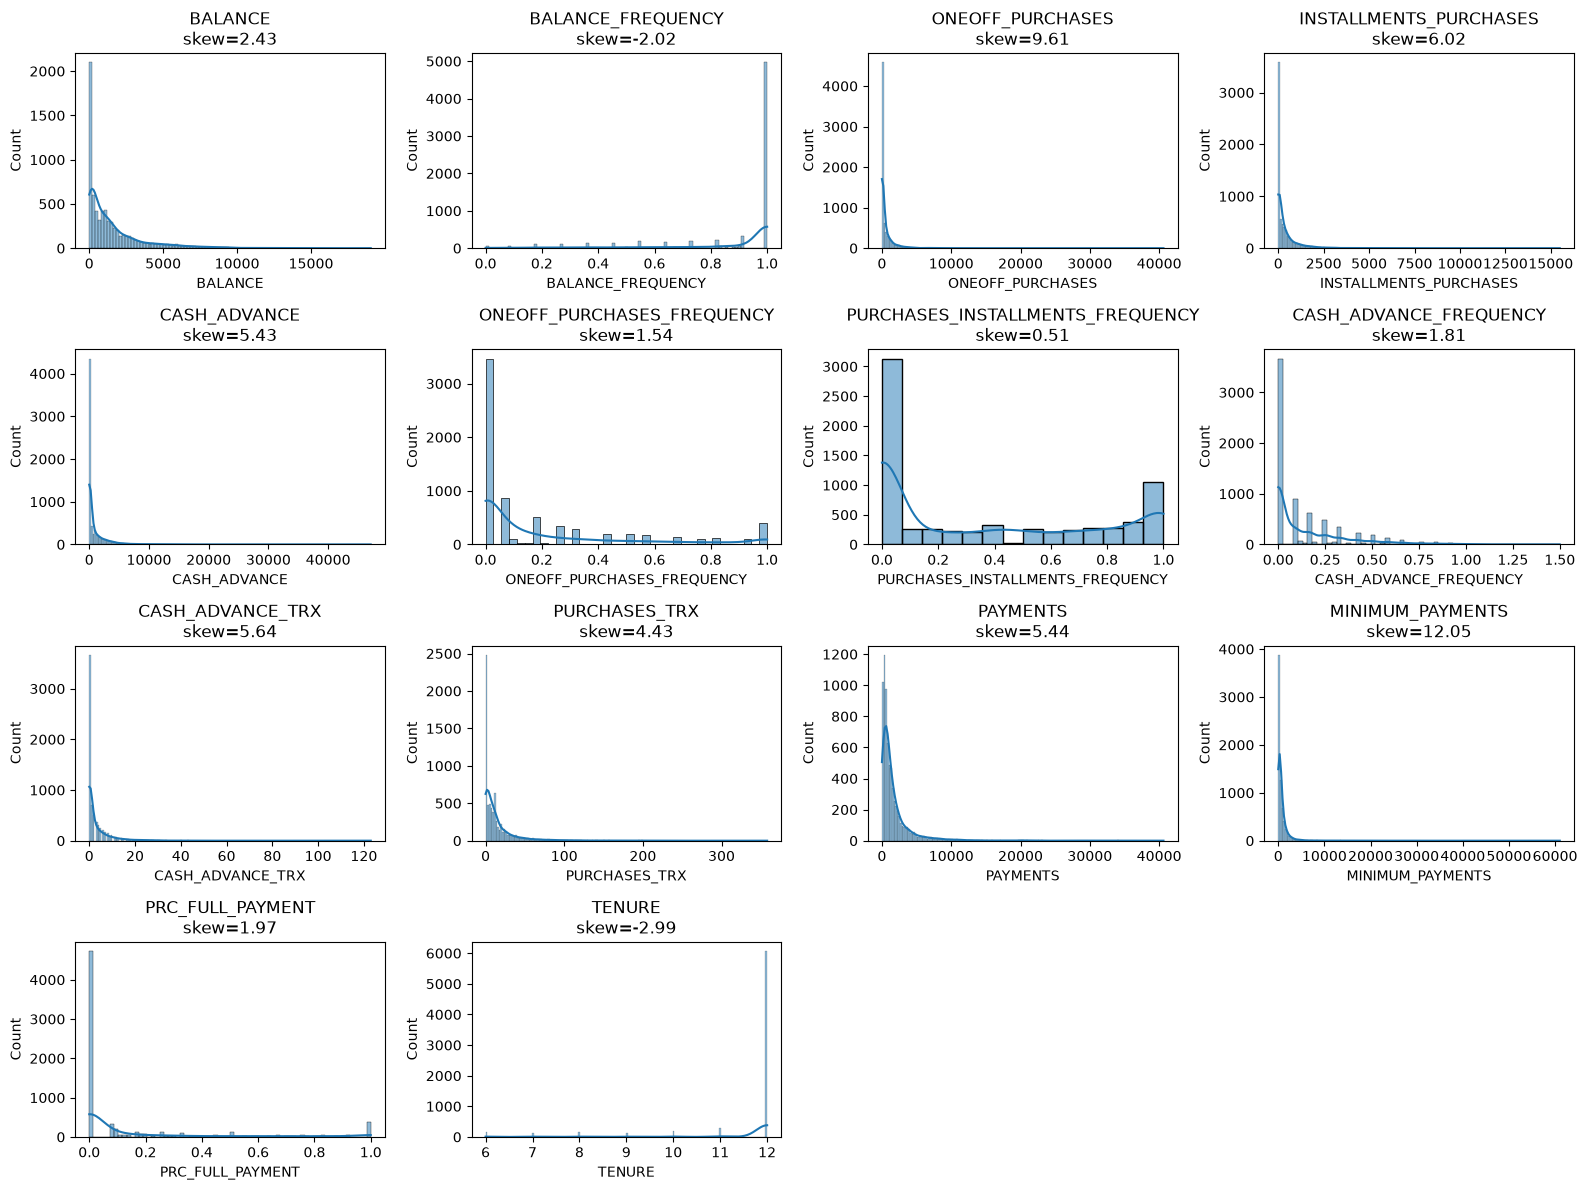

In [110]:
#revision visual de la simetria
cols = X_train.columns
n_cols = 4
n_rows = -(-len(cols) // n_cols)  # redondeo hacia arriba

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 4, n_rows * 3))
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.histplot(X_train[col], kde=True, ax=axes[i])
    axes[i].set_title(f"{col}\nskew={X_train[col].skew():.2f}")

# Ocultar subplots sobrantes si las columnas no llenan la cuadrícula
for j in range(len(cols), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

In [111]:
#Revisar el target
print(y_train.describe())
print("Skew:", round(y_train.skew(), 2))
print("Cuantiles 90/95/99:", y_train.quantile([.90, .95, .99]).round(0).tolist())

count     7159.000000
mean      4516.765793
std       3665.912470
min        150.000000
25%       1500.000000
50%       3000.000000
75%       6500.000000
max      30000.000000
Name: CREDIT_LIMIT, dtype: float64
Skew: 1.5
Cuantiles 90/95/99: [9500.0, 12000.0, 17000.0]


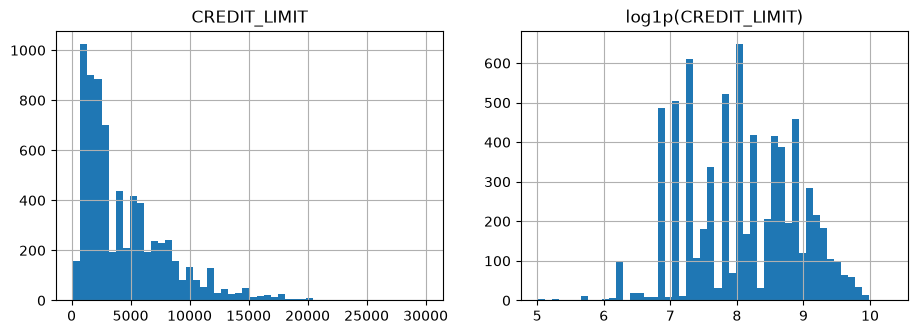

In [112]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
y_train.hist(bins=50, ax=ax[0]);ax[0].set_title("CREDIT_LIMIT")
np.log1p(y_train).hist(bins=50, ax=ax[1]);ax[1].set_title("log1p(CREDIT_LIMIT)")

plt.show()

In [113]:
#Evaluacion para aplicar escaler en base a la asimetria

scaler_dict = {"StandardScaler":StandardScaler,
               "RobustScaler":RobustScaler,}

def scaler(skew_value):
    
    abs_skew = abs(skew_value)
    if abs_skew <= 0.5:
        return "StandardScaler"
    else:
        return "RobustScaler"
    
transformers = []

for col, skew in X_train.skew().items():
    nombre_scaler = scaler(skew)          # "StandardScaler" o "RobustScaler"
    clase_scaler = scaler_dict[nombre_scaler]  # la clase, ej. StandardScaler
    instancia_scaler = clase_scaler()          # el objeto ya creado, ej. StandardScaler()

    transformador = (col, instancia_scaler, [col])
    transformers.append(transformador)

preprocesador = ColumnTransformer(transformers, verbose_feature_names_out=False)

X_train_scaled = preprocesador.fit_transform(X_train)
X_test_scaled = preprocesador.transform(X_test)    

In [114]:
#Transformacion de target Y
y_train_transf = np.log1p(y_train)
y_test_transf = np.log1p(y_test)

In [115]:
#Validacion de estandarizadores (scalers) aplicados
Skew=X_train.skew().sort_values(ascending=False).to_frame(name = "Skew_Value")
Skew["Scaler_aplicado"] = Skew["Skew_Value"].apply(scaler)
Skew

,Skew_Value,Scaler_aplicado
MINIMUM_PAYMENTS,12.046193,RobustScaler
ONEOFF_PURCHASES,9.611403,RobustScaler
INSTALLMENTS_PURCHASES,6.024245,RobustScaler
CASH_ADVANCE_TRX,5.636638,RobustScaler
PAYMENTS,5.440596,RobustScaler
CASH_ADVANCE,5.428087,RobustScaler
PURCHASES_TRX,4.433626,RobustScaler
BALANCE,2.433997,RobustScaler
PRC_FULL_PAYMENT,1.966065,RobustScaler
CASH_ADVANCE_FREQUENCY,1.812613,RobustScaler


6. Modelado (Modeling)

In [116]:
#intastancias lineales
lr = LinearRegression()
lasso = Lasso(alpha=1.0,random_state=42)
ridge = Ridge(alpha=1.0,random_state=42)

In [117]:
#intastancias no lineales
RFR = RandomForestRegressor(n_estimators= 50,random_state= 42)
HGBR = HistGradientBoostingRegressor(loss="squared_error",
                                     learning_rate=.03,
                                     max_iter=1000,
                                     early_stopping=True,
                                     random_state=42)

In [118]:
#Entrenamiento LinearRegression
lr.fit(X_train_scaled,y_train)
y_predict_lr = lr.predict(X_test_scaled)

In [119]:
#Entrenamiento Lasso
lasso.fit(X_train_scaled,y_train)
y_predict_lasso = lasso.predict(X_test_scaled)

In [120]:
#Entrenamiento Ridge
ridge.fit(X_train_scaled,y_train)
y_predict_ridge = ridge.predict(X_test_scaled)

In [121]:
#Entrenamiento RandomForest
RFR.fit(X_train,y_train)
y_predict_RFR = RFR.predict(X_test)

In [122]:
#Entrenamiento HistGrandient
HGBR.fit(X_train,y_train)
y_predict_HGBR = HGBR.predict(X_test)
print(HGBR.n_iter_)

173


7. Evaluación (Evaluation)

In [123]:
kf = KFold(
    n_splits= 5,
    shuffle= True,
    random_state= 42
)

In [124]:
#Estructura de HistGradientBoost Tunned (hiperparametros)
param_grid_ridge = {"alpha": [0.01, 0.1, 1, 10, 100, 300, 1000]}
grid_ridge = GridSearchCV(estimator=ridge,
                         param_grid = param_grid_ridge,
                         cv = kf,
                         scoring= "neg_root_mean_squared_error"          
)
#Estructura de Lasso Tunned (hiperparametros)
param_grid_lasso = {"alpha": [0.001, 0.01, 0.1, 1, 5, 10, 50]}
grid_lasso = GridSearchCV(estimator=lasso,
                         param_grid = param_grid_lasso,
                         cv = kf,
                         scoring= "neg_root_mean_squared_error"          
)
#Estructura de RandomForestRegression Tunned (hiperparametros)
param_grid_RFR = {
    "n_estimators":[200],
    "max_depth" :[5,10,20,None],
    "min_samples_leaf" : [1,5,10,20],
    "max_features" : [.33,.5,.75,1.0]
}

grid_RFR = GridSearchCV(estimator=RFR,
                        param_grid= param_grid_RFR,
                        cv= kf,
                        scoring="neg_root_mean_squared_error"                                     
)
#Estructura de HistGradientBoost Tunned(hiperparametros)
param_grid_HGBR = {"learning_rate":[.03,.05,0.1],
                   "max_leaf_nodes":[8,15,31],
                   "min_samples_leaf" : [20,50,100],
                   "l2_regularization" : [0,1,10]
}

HGBR_grid = HistGradientBoostingRegressor(loss="squared_error",
                                     learning_rate=.03,
                                     max_iter=1000,
                                     early_stopping=True,
                                     random_state=42)

grid_HGBR = GridSearchCV(estimator=HGBR_grid,
                         param_grid=param_grid_HGBR,
                         cv = kf,
                         scoring="neg_root_mean_squared_error",
                         n_jobs=-1)

In [125]:
#Entrenamiento de modelos con CV Ridge
grid_r = grid_ridge.fit(X_train_scaled, y_train)
y_grid_r = grid_ridge.predict(X_test_scaled)

In [126]:
#Entrenamiento de modelos con hiperparametros CV Lasso
grid_l = grid_lasso.fit(X_train_scaled, y_train)
y_grid_l = grid_lasso.predict(X_test_scaled)

In [127]:
#Entrenamiento de modelos con CV RandomForest
grid_RF = grid_RFR.fit(X_train,y_train)
y_grid_RF = grid_RFR.predict(X_test)

In [128]:
#Entrenamiento de modelos con CV HistGradientBoosting
grid_HGBR = grid_HGBR.fit(X_train,y_train)
y_grid_HGBR = grid_HGBR.predict(X_test)

In [129]:
#Mejores Parametros
alpha_r = grid_r.best_params_["alpha"]
alpha_l = grid_l.best_params_["alpha"]
best_RF = grid_RFR.best_params_
best_HG = grid_HGBR.best_params_

In [130]:
#intastancias, se añaden los hyperparametros ya que best_params no los considerar en sus elementos
lasso_grid = Lasso(alpha= alpha_l,random_state=42)
ridge_grid = Ridge(alpha=alpha_r,random_state=42)
RFR_grid = RandomForestRegressor(**best_RF,random_state=42)
HGBR_grid = HistGradientBoostingRegressor(**best_HG,max_iter=1000,early_stopping=True,random_state=42,)

In [131]:
#Entrenamiento Lasso
lasso_grid.fit(X_train_scaled,y_train)
y_predict_gdrl = lasso_grid.predict(X_test_scaled)

In [132]:
#Entrenamiento Ridge
ridge_grid.fit(X_train_scaled,y_train)
y_predict_grdr=ridge_grid.predict(X_test_scaled)

In [133]:
#Entrenamiento RandomForest
RFR_grid.fit(X_train,y_train)
y_predict_grRFR = RFR_grid.predict(X_test)

In [134]:
#Entrenamiento GradientBoosting
HGBR_grid.fit(X_train,y_train)
y_predict_grHGBR = HGBR_grid.predict(X_test)
print(HGBR_grid.n_iter_)

109


In [135]:
grid_results = pd.DataFrame({
       "R2":[r2_score(y_test, y_predict_lr),
             r2_score(y_test, y_predict_lasso),
             r2_score(y_test, y_predict_ridge),
             r2_score(y_test, y_predict_RFR),
             r2_score(y_test, y_predict_HGBR)],
       "R2_grid":[r2_score(y_test, y_predict_lr),
                  r2_score(y_test, y_predict_lasso),
                  r2_score(y_test, y_predict_grdr),
                  r2_score(y_test, y_predict_grRFR),
                  r2_score(y_test,y_predict_grHGBR)],
    "RMSE":[root_mean_squared_error(y_test, y_predict_lr),
            root_mean_squared_error(y_test, y_predict_lasso),
            root_mean_squared_error(y_test, y_predict_ridge),
            root_mean_squared_error(y_test, y_predict_RFR),
            root_mean_squared_error(y_test, y_predict_HGBR)],
    "RMSE_grid":[root_mean_squared_error(y_test, y_predict_lr),
                 root_mean_squared_error(y_test, y_predict_gdrl),
                 root_mean_squared_error(y_test, y_predict_grdr),
                 root_mean_squared_error(y_test, y_predict_grRFR),
                 root_mean_squared_error(y_test, y_predict_grHGBR)],
    "MAE":[mean_absolute_error(y_test,y_predict_lr),
           mean_absolute_error(y_test,y_predict_lasso),
           mean_absolute_error(y_test,y_predict_ridge),
           mean_absolute_error(y_test,y_predict_RFR),
           mean_absolute_error(y_test,y_predict_HGBR)],
    "MAE_grid":[mean_absolute_error(y_test, y_predict_lr),
                mean_absolute_error(y_test, y_predict_gdrl),
                mean_absolute_error(y_test, y_predict_grdr),
                mean_absolute_error(y_test, y_predict_grRFR),
                mean_absolute_error(y_test, y_predict_grHGBR)],
    
}, index=["LinearRegression", "Lasso", "Ridge", "RandomForest","Gradient Boost"])

grid_results.round(3)

,R2,R2_grid,RMSE,RMSE_grid,MAE,MAE_grid
LinearRegression,0.454,0.454,2607.154,2607.154,1934.485,1934.485
Lasso,0.454,0.454,2606.989,2606.989,1934.576,1934.576
Ridge,0.454,0.454,2607.134,2606.954,1934.480,1934.437
RandomForest,0.465,0.494,2579.863,2508.799,1806.020,1754.658
Gradient Boost,0.500,0.496,2493.983,2504.361,1742.439,1745.633


In [136]:
best_index=grid_results.sort_values("RMSE_grid",ascending=True).index[0]
best_value = grid_results.loc[best_index, "RMSE_grid"]

In [137]:
#CV grid comprativa de R2
cv_score_lasso = cross_val_score(estimator=lasso,
                                 X=X_train_scaled,
                                 y= y_train,
                                 cv=kf)
cv_score_lasso_grid = cross_val_score(estimator= lasso_grid,
                                      X=X_train_scaled,
                                      y=y_train,
                                      cv=kf)
cv_score_ridge =cross_val_score(estimator=ridge,
                                X=X_train_scaled,
                                y=y_train,
                                cv=kf) 
cv_score_ridge_grid = cross_val_score(estimator=ridge_grid,
                                      X=X_train_scaled,
                                      y=y_train,
                                      cv=kf)
cv_score_RFR = cross_val_score(estimator=RFR,
                               X=X_train,
                               y=y_train,
                               cv=kf)
cv_score_RFR_grid = cross_val_score(estimator=RFR_grid,
                                    X=X_train,
                                    y=y_train,
                                    cv=kf)
cv_score_HGBR = cross_val_score(estimator=HGBR,
                                X=X_train,
                                y=y_train,
                                cv=kf)
v_score_HGBR_grid = cross_val_score(estimator=HGBR_grid,
                                X=X_train,
                                y=y_train,
                                cv=kf)

scores_vs_grid = pd.DataFrame({
    "Lasso R2":cv_score_lasso,
    "Lasso grid":cv_score_lasso_grid,
    "Ridge R2" : cv_score_ridge,
    "Ridge grid" : cv_score_ridge_grid,
    "RandomForest R2" : cv_score_RFR,
    "RandomForest grid" : cv_score_RFR_grid,
    "Gradient Boost R2" : cv_score_HGBR,
    "Gradient Boost grid" : v_score_HGBR_grid 
})
scores_vs_grid.round(3)

,Lasso R2,Lasso grid,Ridge R2,Ridge grid,RandomForest R2,RandomForest grid,Gradient Boost R2,Gradient Boost grid
0,0.427,0.427,0.427,0.427,0.495,0.516,0.511,0.511
1,0.433,0.433,0.433,0.433,0.496,0.519,0.502,0.507
2,0.460,0.460,0.460,0.460,0.507,0.534,0.545,0.546
3,0.422,0.422,0.422,0.422,0.485,0.501,0.501,0.508
4,0.514,0.514,0.513,0.513,0.560,0.582,0.579,0.584


In [138]:
scores_vs_grid_2 = scores_vs_grid.agg(["std","mean"])
scores_vs_grid_2

,Lasso R2,Lasso grid,Ridge R2,Ridge grid,RandomForest R2,RandomForest grid,Gradient Boost R2,Gradient Boost grid
std,0.03783,0.03783,0.037825,0.037822,0.029635,0.030771,0.033771,0.033655
mean,0.45110,0.45110,0.451098,0.451102,0.508484,0.530395,0.527616,0.531142


In [139]:
best_R2_index = scores_vs_grid_2.max().idxmax()
best_R2_value = scores_vs_grid_2[best_R2_index].max()

In [140]:
print("Los modelos de árboles (RandomForest y Gradient Boost) superan a los lineales: "
      "R² ≈ 0.49-0.50 vs 0.454 en test, y RMSE ≈ 2 500 vs 2 607.\n"
      "Entre RandomForest y Gradient Boost la diferencia es de ~0.2% en RMSE, "
      "dentro del ruido de la validación cruzada (std ≈ 0.03), por lo que se consideran equivalentes.\n"
      "El ajuste de hiperparámetros no produjo mejoras relevantes.")

Los modelos de árboles (RandomForest y Gradient Boost) superan a los lineales: R² ≈ 0.49-0.50 vs 0.454 en test, y RMSE ≈ 2 500 vs 2 607.
Entre RandomForest y Gradient Boost la diferencia es de ~0.2% en RMSE, dentro del ruido de la validación cruzada (std ≈ 0.03), por lo que se consideran equivalentes.
El ajuste de hiperparámetros no produjo mejoras relevantes.


In [141]:
#Entrenamiento de modelo con el target transformado RFR
RFR_grid.fit(X_train,y_train_transf)
y_pred_RFR_log = np.expm1(RFR_grid.predict(X_test))

In [142]:
#Entrenamiento de modelo con el target transformado HGBR
HGBR_grid.fit(X_train,y_train_transf)
y_pred_HGBR_log = np.expm1(HGBR_grid.predict(X_test))

In [143]:
log_result = pd.DataFrame({
    "R2_log":[r2_score(y_test,y_pred_RFR_log),
              r2_score(y_test,y_pred_HGBR_log)],
    "R2_grid":[r2_score(y_test, y_predict_RFR),
               r2_score(y_test, y_predict_HGBR)],
    "RMSE_log":[root_mean_squared_error(y_test,y_pred_RFR_log),
                 root_mean_squared_error(y_test,y_pred_HGBR_log)],
    "RMSE_grid":[root_mean_squared_error(y_test, y_predict_grRFR),
                root_mean_squared_error(y_test, y_predict_grHGBR)],
    "MAE_log":[mean_absolute_error(y_test,y_pred_RFR_log),
               mean_absolute_error(y_test,y_pred_HGBR_log)],
    "Mae_grid":[mean_absolute_error(y_test, y_predict_grRFR),
               mean_absolute_error(y_test, y_predict_grHGBR)],
},index=["RandomForest","Gradient Boost"])

log_result.round(2)

,R2_log,R2_grid,RMSE_log,RMSE_grid,MAE_log,Mae_grid
RandomForest,0.46,0.46,2588.87,2508.80,1664.78,1754.66
Gradient Boost,0.46,0.50,2589.95,2504.36,1671.00,1745.63


¿Qué variables afectan más? (importancia, SHAP, LIME)

¿El modelo es interpretable para el negocio?

¿Tiene sentido lo que aprendió?

9. Despliegue (Deployment)

Convertir el modelo a producción (API, servicio)

Herramientas: FastAPI, Flask, Docker, MLflow, cloud (AWS, GCP, Azure)

Escalar y monitorear

10. Monitoreo y mantenimiento (MLOps)

Detectar data drift (los datos cambian con el tiempo)

Detectar model drift (el modelo pierde precisión)

Reentrenamiento periódico

Logs y alertas